In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully")

Libraries loaded successfully


In [2]:
df = pd.read_csv("data/combined_data.csv")

print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nMissing values:\n", df.isnull().sum())
df.head()

Shape: (83448, 2)

Columns: ['label', 'text']

Missing values:
 label    0
text     0
dtype: int64


,label,text
0,1,ounce feather bowl hummingbird opec moment ala...
1,1,wulvob get your medircations online qnb ikud v...
2,0,computer connection from cnn com wednesday es...
3,1,university degree obtain a prosperous future m...
4,0,thanks for all your answers guys i know i shou...


label
1    43910
0    39538
Name: count, dtype: int64

label
1    52.62
0    47.38
Name: proportion, dtype: float64


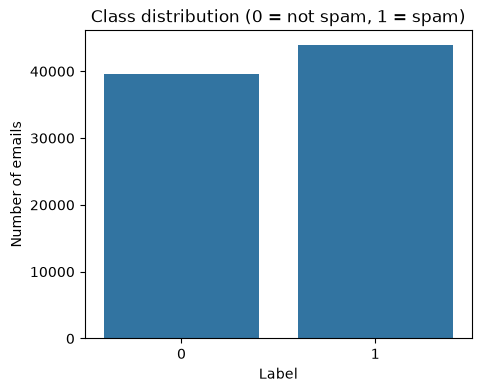

In [3]:
print(df['label'].value_counts())
print()
print((df['label'].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(5, 4))
sns.countplot(x='label', data=df)
plt.title("Class distribution (0 = not spam, 1 = spam)")
plt.xlabel("Label")
plt.ylabel("Number of emails")
plt.show()

In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate texts:", df['text'].duplicated().sum())

word_counts = df['text'].str.split().str.len()
print("\nWord count statistics:")
print(word_counts.describe())
print("\nEmpty texts:", (word_counts == 0).sum())

Duplicate rows: 0
Duplicate texts: 2

Word count statistics:
count     83448.000000
mean        282.811775
std         724.818152
min           1.000000
25%          80.000000
50%         152.000000
75%         312.000000
max      101984.000000
Name: text, dtype: float64

Empty texts: 0


In [5]:
for lbl in [0, 1]:
    print(f"--- label {lbl} ---")
    for t in df[df['label'] == lbl]['text'].head(2):
        print(t[:300], "\n")

--- label 0 ---
 computer connection from cnn com wednesday escapenumber may escapenumber escapenumber escapenumber escapenumber pm edt in this report next generation toys read brain waves google expands personalization youtube wins webby old fashioned rabbit ears laptop review next generation toys read brain waves 

thanks for all your answers guys i know i should have checked the rsync manual but i would rather get a escapenumber sure answer from one of you this is my current script bin bash rsync avt \\ exclude alpha \\ exclude arm \\ exclude hppa \\ exclude hurd \\ exclude iaescapenumber \\ exclude mescapenu 

--- label 1 ---
ounce feather bowl hummingbird opec moment alabaster valkyrie dyad bread flack desperate iambic hadron heft quell yoghurt bunkmate divert afterimage 

wulvob get your medircations online qnb ikud viagra escapenumber escapenumber levitra escapenumber escapenumber cialis escapenumber escapenumber imitrex escapenumber escapenumber flonax escapenumber escapenumber

In [6]:
import re

# Drop every copy of the 2 duplicated texts (loses at most a few rows)
df = df.drop_duplicates(subset='text', keep=False).reset_index(drop=True)

def clean_text(t):
    t = t.lower()
    t = t.replace('escapenumber', ' ')
    t = re.sub(r'[^a-z\s]', ' ', t)
    t = re.sub(r'\s+', ' ', t).strip()
    return t

df['clean_text'] = df['text'].apply(clean_text)

# Remove emails that became empty after cleaning
df = df[df['clean_text'].str.len() > 0].reset_index(drop=True)

print("Shape after cleaning:", df.shape)
df[['text', 'clean_text']].head(3)

Shape after cleaning: (83382, 3)


,text,clean_text
0,ounce feather bowl hummingbird opec moment ala...,ounce feather bowl hummingbird opec moment ala...
1,wulvob get your medircations online qnb ikud v...,wulvob get your medircations online qnb ikud v...
2,computer connection from cnn com wednesday es...,computer connection from cnn com wednesday may...


In [7]:
from sklearn.model_selection import train_test_split

X = df['clean_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training emails:", X_train.shape[0])
print("Test emails:", X_test.shape[0])
print("\nSpam % in training:", round(y_train.mean() * 100, 2))
print("Spam % in test:", round(y_test.mean() * 100, 2))

Training emails: 66705
Test emails: 16677

Spam % in training: 52.59
Spam % in test: 52.59


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=50000,
    min_df=5,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix shape:", X_train_tfidf.shape)
print("Test matrix shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.get_feature_names_out()))

Training matrix shape: (66705, 50000)
Test matrix shape: (16677, 50000)
Vocabulary size: 50000


In [9]:
feature_names = tfidf.get_feature_names_out()
print("Sample words from the vocabulary:", list(feature_names[1000:1015]))

i = 0
row = X_train_tfidf[i]
top_idx = row.toarray().ravel().argsort()[::-1][:10]

print("\nLabel of this email:", y_train.iloc[i], "(1 = spam, 0 = not spam)")
print("Top 10 highest-weighted words in this email:")
for j in top_idx:
    print(f"  {feature_names[j]:<20} {row[0, j]:.3f}")

Sample words from the vocabulary: ['affords', 'afforest', 'afforrdable', 'affricate', 'affront', 'affymetrix', 'afghan', 'afghanistan', 'aficionado', 'aficionados', 'afield', 'afile', 'afin', 'afire', 'afirma']

Label of this email: 0 (1 = spam, 0 = not spam)
Top 10 highest-weighted words in this email:
  fflush               0.241
  tctx                 0.218
  torture              0.218
  stdout               0.186
  nbt                  0.167
  printf               0.160
  collisions           0.156
  denytest             0.155
  count                0.151
  bool                 0.147


In [10]:
import time
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

start = time.time()
nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)
nb_pred = nb.predict(X_test_tfidf)
print("Training + prediction time:", round(time.time() - start, 2), "seconds\n")

print("Naive Bayes")
print("Accuracy :", round(accuracy_score(y_test, nb_pred), 4))
print("Precision:", round(precision_score(y_test, nb_pred), 4))
print("Recall   :", round(recall_score(y_test, nb_pred), 4))
print("F1-score :", round(f1_score(y_test, nb_pred), 4))
print()
print(classification_report(y_test, nb_pred, target_names=['Not spam', 'Spam']))

Training + prediction time: 0.28 seconds

Naive Bayes
Accuracy : 0.9707
Precision: 0.9836
Recall   : 0.9602
F1-score : 0.9718

              precision    recall  f1-score   support

    Not spam       0.96      0.98      0.97      7906
        Spam       0.98      0.96      0.97      8771

    accuracy                           0.97     16677
   macro avg       0.97      0.97      0.97     16677
weighted avg       0.97      0.97      0.97     16677



In [11]:
from sklearn.linear_model import LogisticRegression

start = time.time()
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_tfidf, y_train)
lr_pred = lr.predict(X_test_tfidf)
print("Training + prediction time:", round(time.time() - start, 2), "seconds\n")

print("Logistic Regression")
print("Accuracy :", round(accuracy_score(y_test, lr_pred), 4))
print("Precision:", round(precision_score(y_test, lr_pred), 4))
print("Recall   :", round(recall_score(y_test, lr_pred), 4))
print("F1-score :", round(f1_score(y_test, lr_pred), 4))
print()
print(classification_report(y_test, lr_pred, target_names=['Not spam', 'Spam']))

Training + prediction time: 0.67 seconds

Logistic Regression
Accuracy : 0.9868
Precision: 0.9808
Recall   : 0.9944
F1-score : 0.9875

              precision    recall  f1-score   support

    Not spam       0.99      0.98      0.99      7906
        Spam       0.98      0.99      0.99      8771

    accuracy                           0.99     16677
   macro avg       0.99      0.99      0.99     16677
weighted avg       0.99      0.99      0.99     16677



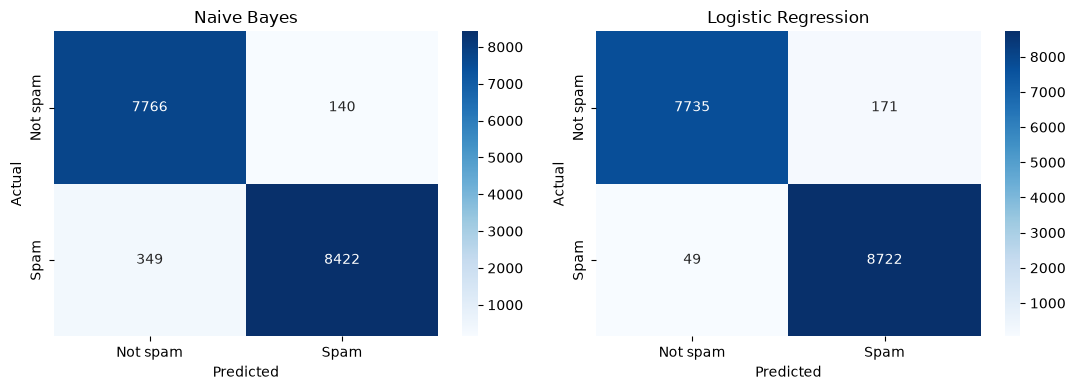

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, pred, name in zip(axes, [nb_pred, lr_pred], ['Naive Bayes', 'Logistic Regression']):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Not spam', 'Spam'], yticklabels=['Not spam', 'Spam'])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [13]:
results = pd.DataFrame({
    'Model': ['Naive Bayes', 'Logistic Regression'],
    'Accuracy': [accuracy_score(y_test, nb_pred), accuracy_score(y_test, lr_pred)],
    'Precision': [precision_score(y_test, nb_pred), precision_score(y_test, lr_pred)],
    'Recall': [recall_score(y_test, nb_pred), recall_score(y_test, lr_pred)],
    'F1-score': [f1_score(y_test, nb_pred), f1_score(y_test, lr_pred)]
}).round(4)

results

,Model,Accuracy,Precision,Recall,F1-score
0,Naive Bayes,0.9707,0.9836,0.9602,0.9718
1,Logistic Regression,0.9868,0.9808,0.9944,0.9875


In [14]:
coefs = lr.coef_[0]

top_spam = np.argsort(coefs)[::-1][:15]
top_ham = np.argsort(coefs)[:15]

print("Top 15 words pushing toward SPAM:")
for j in top_spam:
    print(f"  {feature_names[j]:<20} {coefs[j]:.2f}")

print("\nTop 15 words pushing toward NOT SPAM:")
for j in top_ham:
    print(f"  {feature_names[j]:<20} {coefs[j]:.2f}")

Top 15 words pushing toward SPAM:
  life                 4.44
  hk                   4.17
  quality              3.73
  money                3.68
  info                 3.49
  men                  3.30
  adf                  3.11
  target               3.05
  man                  3.01
  reply                3.00
  stop                 2.99
  product              2.96
  online               2.96
  remove               2.94
  offer                2.92

Top 15 words pushing toward NOT SPAM:
  enron                -12.89
  wrote                -10.96
  thanks               -8.42
  samba                -7.41
  perl                 -7.33
  attached             -7.25
  vince                -7.14
  louise               -6.39
  debian               -5.95
  org                  -5.80
  lists                -5.54
  questions            -5.34
  pm                   -5.23
  gas                  -4.89
  doc                  -4.80


In [15]:
samples = [
    "Congratulations! You have won a free prize. Click here to claim your cash reward now",
    "Hi team, attaching the meeting notes from yesterday. Please review before Friday",
    "Cheap online pharmacy, buy viagra and cialis with no prescription, huge discount",
    "Can you send me the project report by tomorrow? Thanks"
]

cleaned = [clean_text(s) for s in samples]
vec = tfidf.transform(cleaned)
preds = lr.predict(vec)
probs = lr.predict_proba(vec)[:, 1]

for s, p, pr in zip(samples, preds, probs):
    label = "SPAM" if p == 1 else "NOT SPAM"
    print(f"{label:<9} (spam probability {pr:.2f})  ->  {s[:70]}")

SPAM      (spam probability 0.89)  ->  Congratulations! You have won a free prize. Click here to claim your c
NOT SPAM  (spam probability 0.02)  ->  Hi team, attaching the meeting notes from yesterday. Please review bef
SPAM      (spam probability 1.00)  ->  Cheap online pharmacy, buy viagra and cialis with no prescription, hug
NOT SPAM  (spam probability 0.01)  ->  Can you send me the project report by tomorrow? Thanks
